# MECHA in metafspm, 1: coupling GRANAP's anatomies and MECHA's hydraulics

This tutorial is for MECHA developers. It shows how MECHA's port runs on anatomies generated by GRANAP, through
metafspm, on one root cross section:

- **No file between the two.** The legacy reads a GRANAR/CellSet XML and builds its own network. In metafspm,
  GRANAP writes each section's network into the plant graph (its `Compartment`s and `Connection`s, with their
  tissue, areas, lengths) and MECHA reads it from the shared DataStructure, as declared inputs.
- **MECHA is a component.** `MechaHydraulics` is a metafspm `FunctionalComponent`: its inputs, parameters and
  outputs are declared with units, and each input names the role of the model that provides it (`Anatomy`:
  GRANAP; `Development`: the apoplastic barriers; `Soil`; `Solutes`; `Transpiration`...). Any model providing the
  same variables can replace another.
- **Its problems are graph systems.** The conductances are rate steps (per edge, vectorized); MECHA's *standard
  problem* (each section alone: its kr) and the *plant problem* (every section of a plant joined by its xylem
  junctions, with the soil around and a collar or the transpiration as boundaries) are metafspm `graph_system`s,
  assembled and solved by metafspm on the whole DataStructure.
- **One section or a plant: the same code.** The next tutorials put a soil gradient around this section, then
  solve a pine needle's sections with solutes, then a whole plant in its soil.

In [1]:
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from openalea.metafspm.coupling.choregrapher import Choregrapher
from openalea.metafspm.coupling.component import StructuralComponent
from openalea.metafspm.data_structure.configs import PropsConfig
from openalea.metafspm.data_structure.data_api import MPGDataStructure
from openalea.metafspm.scene.population import build_population

from openalea.granap.metafspm.component import GranapAnatomy, junction_rules
from openalea.mecha import plots
from openalea.mecha.component import MechaHydraulics

Choregrapher().add_simulation_time_step(3600.)          # metafspm's simulation time step (s)

## 1. The section: an architecture and GRANAP's anatomy

A stand-in for an architecture model gives one root segment (radius, length, distance from the tip); GRANAP's
component gives it its anatomy (its default library: the monocot root preset). See GRANAP's tutorial for the
anatomy side (`GRANAP/example/tutorials`).

In [2]:
RADIUS, LENGTH = 0.55e-3, 2e-4                          # m: GRANAP's monocot root preset, a 200 µm section


class OneSegmentRoot(StructuralComponent):
    @classmethod
    def initiate_plant(cls, g, plant, parameters):
        s, L = g.scales, g.labels
        complex_ = plant
        for scale, label in ((s.Axis, L.Axis.Root), (s.GrowthUnit, L.GrowthUnit.Root), (s.Phytomer, L.Phytomer.Root),
                             (s.Organ, L.Organ.RootInternode)):
            complex_ = g.add_component(complex_, **PropsConfig(scale=scale, edge_type='/', label=label))
        segment = g.add_component(complex_, **PropsConfig(scale=s.SubOrgan, edge_type='/',
                                                          label=L.SubOrgan.RootSegment))
        g.property("radius")[segment] = RADIUS
        g.property("length")[segment] = LENGTH
        g.property("distance_from_tip")[segment] = 0.


plants = pd.DataFrame([dict(plant="p0", model=None, x=0., y=0., z=0., rotation=0., scenario={"parameters": {}})])
g, _ = build_population(plants, initiators=(OneSegmentRoot, GranapAnatomy))
g.convert_properties_to_arraydict()
ds = MPGDataStructure(g, from_scale=g.scales.SubOrgan, nodes="Compartment", wiring=junction_rules(g))
anatomy = GranapAnatomy(data_structure=ds)
anatomy()
segment = int(ds.entity_ids("SubOrgan")[0])
print(f"{ds.n_nodes()} Compartments (protoplasts, walls, wall junctions), {ds.n_edges()} Connections")

8269 Compartments (protoplasts, walls, wall junctions), 20334 Connections


## 2. MECHA's component on the same DataStructure

`MechaHydraulics` declares what it reads. The variables GRANAP writes (role `Anatomy`) are already in the
DataStructure; the others are given by other models in a full simulation, or by hand here:

- `barrier` (role `Development`): MECHA's maturity code of the apoplastic barriers, per Compartment (0 none,
  1 endodermal Casparian strip, 2 suberized endodermis with passage cells, 3 fully suberized, 4 + exodermal strip);
- `soil_psi` (role `Soil`, hPa) for the plant problem, 0 by default;
- `osmotic_potential`, `reflection_coefficient` (role `Solutes`), 0 by default: no osmotic terms.

In [3]:
inputs = [(name, f.metadata.get("by"), f.metadata.get("unit"), f.metadata.get("description"))
          for name, f in MechaHydraulics.__dataclass_fields__.items() if f.metadata.get("variable_type") == "input"]
pd.set_option("display.max_colwidth", 80)
table = pd.DataFrame(inputs, columns=["input", "role (by)", "unit", "description"]).set_index("input")
table.sort_values("role (by)")

,role (by),unit,description
input,,,
kind,Anatomy,,"0 protoplast, 1 wall, 2 wall junction"
anatomy_template,Anatomy,,the segment's anatomy template (-1: none): sections of the same template sha...
edge_dist,Anatomy,mm,the distance between the edge's nodes
edge_length,Anatomy,mm,the edge's length
pore_depth,Anatomy,mm,a stomatal pore's depth through the epidermis (NaN: not a pore)
pore_width,Anatomy,mm,a stomatal pore's aperture width (NaN: not a pore)
wall_thickness,Anatomy,µm,"the wall's thickness, its two cells' layers (NaN: not a wall; thickness_sour..."
network_path,Anatomy,,"edge type: membrane 0, wall_air 1, wall 2, plasmodesmata 3, air_link 4, axia..."
wall_length,Anatomy,mm,the wall's length in the section (0: not a wall)


In [4]:
granap_outputs = {name for name, f in GranapAnatomy.__dataclass_fields__.items()
                  if f.metadata.get("variable_type") == "state_variable"}
read_from_granap = sorted(set(table.index) & granap_outputs)
print(f"MECHA reads {len(read_from_granap)} of GRANAP's declared outputs:", ", ".join(read_from_granap))

MECHA reads 14 of GRANAP's declared outputs: anatomy_template, cell_area, cgroup, edge_dist, edge_length, kind, network_path, pore_depth, pore_width, section_x, section_y, tissue, wall_length, wall_thickness


In [5]:
ds.register("barrier", np.ones(ds.n_nodes()), location="node")   # the development model's role, by hand
mecha = MechaHydraulics(data_structure=ds)
mecha()                                                           # conductances, then the standard problem
print(f"kr {float(ds.get('kr')[0]):.4e} cm hPa⁻¹ d⁻¹, uptake {float(ds.get('standard_uptake')[0]):.4e} cm³ d⁻¹ "
      f"(soil {mecha.standard_psi_soil:.0f} hPa, xylem {mecha.standard_psi_xylem:.0f} hPa), "
      f"Kx {float(ds.get('Kx')[0]):.3e} cm⁴ hPa⁻¹ d⁻¹")

kr 1.1011e-04 cm hPa⁻¹ d⁻¹, uptake 2.7717e-03 cm³ d⁻¹ (soil 0 hPa, xylem -5000 hPa), Kx 1.194e+00 cm⁴ hPa⁻¹ d⁻¹


### What MECHA computed, as DataStructure variables

Every edge got its conductance `K` (cm³ hPa⁻¹ d⁻¹) by its path: walls (Poiseuille-like apoplastic conductance,
blocked by the barriers), membranes (MECHA's kw/kmb with the aquaporin contributions), plasmodesmata (their
number by tissue); every node its potential in the standard problem, `standard_psi`. `plots.port_frame` reads a
section from the component (and GRANAP's polygons from its library) for MECHA's usual figures.

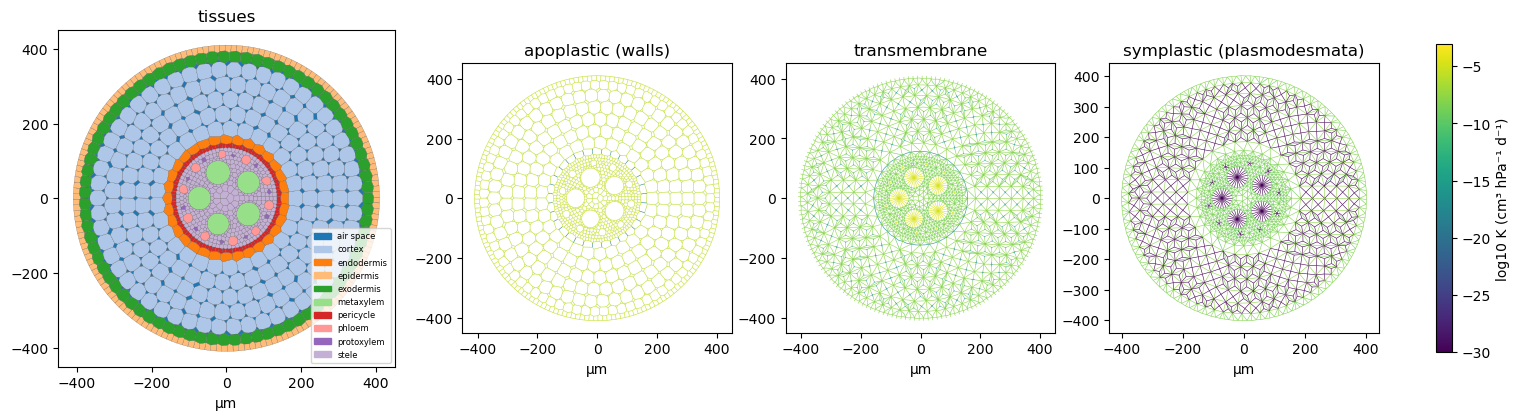

In [6]:
frame = plots.port_frame(mecha, segment, libraries=(GranapAnatomy.library,))
fig, axes = plt.subplots(1, 4, figsize=(20, 5))
plots.tissue_map(axes[0], frame)
lines = plots.conductance_by_path(axes[1:], frame)
fig.colorbar(lines, ax=axes[1:], label="log10 K (cm³ hPa⁻¹ d⁻¹)", shrink=0.8)
plt.show()

## 3. The barriers: a development model's input

`barrier` is an input like any other: changing it and calling the component again recomputes what depends on it
(the walls' conductances, the passage cells' membranes) and the solves. MECHA's legacy maturity stages become one
variable a root development model writes.

In [7]:
results, frames = {}, {}
for barrier in (0, 1, 2, 3, 4):
    ds.set("barrier", np.full(ds.n_nodes(), float(barrier)))
    mecha()
    results[barrier] = dict(kr=float(ds.get("kr")[0]), uptake=float(ds.get("standard_uptake")[0]))
    frames[barrier] = plots.port_frame(mecha, segment, libraries=(GranapAnatomy.library,))
pd.DataFrame(results).T.rename_axis("barrier")

,kr,uptake
barrier,,
0,NaN,-9.827433e-16
1,0.000110,2.771661e-03
2,0.000041,1.024934e-03
3,0.000041,1.024934e-03
4,0.000037,9.422290e-04


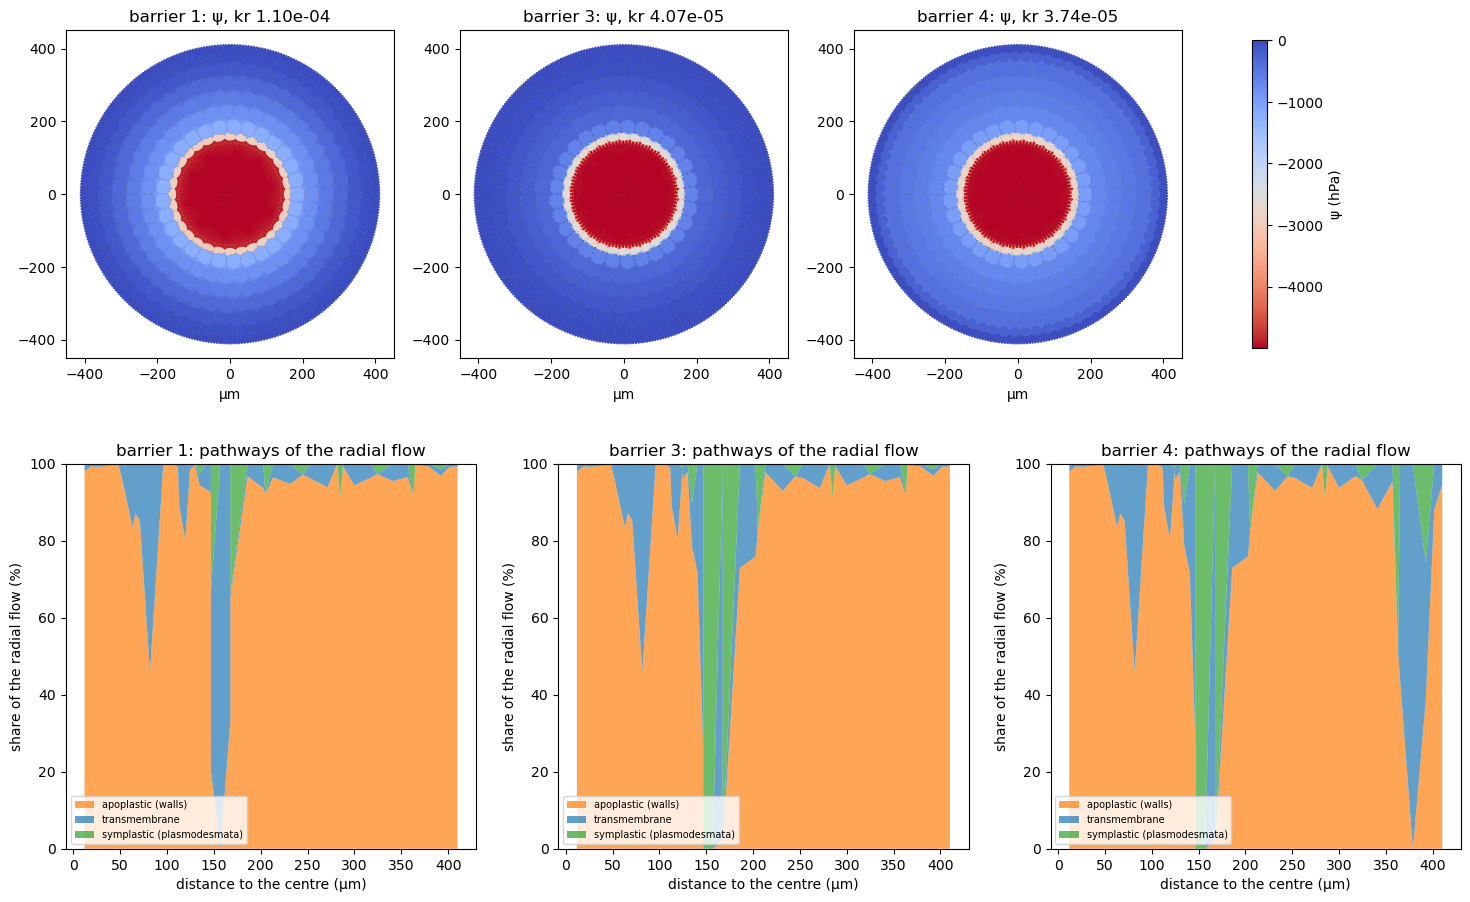

In [8]:
fig, axes = plt.subplots(2, 3, figsize=(18, 11))
norm = matplotlib.colors.Normalize(min(f.psi.min() for f in frames.values()), 0.)
for ax, barrier in zip(axes[0], (1, 3, 4)):
    points = plots.psi_map(ax, frames[barrier], title=f"barrier {barrier}: ψ, kr {results[barrier]['kr']:.2e}",
                           norm=norm)
fig.colorbar(points, ax=axes[0], label="ψ (hPa)", shrink=0.8)
for ax, barrier in zip(axes[1], (1, 3, 4)):
    plots.pathway_breakdown(ax, frames[barrier], title=f"barrier {barrier}: pathways of the radial flow")
plt.show()

## 4. The plant problem on the same section

The standard problem gives MECHA's kr (soil and xylem at fixed potentials, section alone). The *plant problem*
solves the plant as a whole: every section of a plant joined by its axial junctions, the soil's potential around
each border wall and junction (`soil_psi`, role `Soil`, per Compartment), and at the collar (the first root
section's xylem) a potential (`collar_condition` 1, `collar_psi`) or a flow (2). Its solution is `psi`, its flows
`flow` (per edge) and `root_uptake` (per border node). On one section with the soil at the standard problem's
potential, it gives the same uptake.

In [9]:
ds.set("barrier", np.ones(ds.n_nodes()))
mecha.collar_condition, mecha.collar_psi = 1., mecha.standard_psi_xylem
ds.set("soil_psi", np.full(ds.n_nodes(), mecha.standard_psi_soil))
mecha()
print(f"plant problem: uptake {float(ds.get('root_uptake').sum()):.6e} cm³ d⁻¹; "
      f"standard problem: {float(ds.get('standard_uptake')[0]):.6e} cm³ d⁻¹")

plant problem: uptake 2.771670e-03 cm³ d⁻¹; standard problem: 2.771661e-03 cm³ d⁻¹


## 5. The same coupling as a composite model

In a simulation the components are assembled once, as a metafspm `CompositeModel`: its class attributes say how the
population is built (the initiators: architecture, then anatomy; the DataStructure's nodes and wiring), its
`__init__` instantiates the components on the DataStructure and couples them, and `run` is one time step. A
metafspm `Scene` builds the population from these attributes, calls the model at each step, and exchanges with the
environment models (the soil, in the fourth tutorial).

In [10]:
from openalea.metafspm.coupling.composite_wrapper import CompositeModel
from openalea.metafspm.coupling.translator import Translator


class RootSectionHydraulics(CompositeModel):
    """GRANAP's anatomy and MECHA's hydraulics on a root's sections, the barriers given by a development stand-in."""
    initiators = (OneSegmentRoot, GranapAnatomy)
    from_scale = "SubOrgan"
    nodes = "Compartment"
    wiring = junction_rules

    def __init__(self, data_structure, time_step):
        self.anatomy = GranapAnatomy(data_structure=data_structure, time_step=time_step)
        self.anatomy()
        data_structure.register("barrier", np.full(data_structure.n_nodes(), 3.), location="node")
        self.hydraulics = MechaHydraulics(data_structure=data_structure, time_step=time_step)
        # the components' inputs are matched with the others' outputs by name; a Translator adds the links whose
        # names or units differ (the soil's, in the fourth tutorial)
        self.declare_data_and_couple_components(translator_path=Translator(),
                                                components=(self.anatomy, self.hydraulics))

    def run(self):
        self.anatomy()                     # the anatomies of new or changed segments
        self.hydraulics()


g2, _ = build_population(plants, initiators=RootSectionHydraulics.initiators)    # what a Scene does
g2.convert_properties_to_arraydict()
ds2 = MPGDataStructure(g2, from_scale=g2.scales.SubOrgan, nodes="Compartment", wiring=junction_rules(g2))
model = RootSectionHydraulics(ds2, time_step=3600.)
model.run()
print(f"barrier 3: kr {float(ds2.get('kr')[0]):.4e} cm hPa⁻¹ d⁻¹ (the loop above: {results[3]['kr']:.4e})")

barrier 3: kr 4.0717e-05 cm hPa⁻¹ d⁻¹ (the loop above: 4.0717e-05)


## What to take away

- MECHA's science is unchanged and checked against the legacy (`MECHA-dev/test/comparison`: conductances,
  potentials and flows, kr, on GRANAP's sections); its reviewed differences are listed in `devplan_metafspm.md`.
- Its inputs are other models' outputs: anatomy, development, soil, solutes, transpiration. Coupling MECHA to a
  growth model, a soil model or a solute model means providing those variables, not editing MECHA.
- Next: `tutorial_metafspm_02_soil_gradient.ipynb`, the plant problem with a soil potential varying around the
  section.